In [26]:
from astropy.utils.data import download_file
from astropy.io import fits
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS # World Coordinate System

from astropy.convolution import Gaussian2DKernel
from astropy.modeling.models import Lorentz1D
from astropy.convolution import convolve_fft

import matplotlib.pyplot as plt
import numpy as np



In [27]:
file_i = download_file(
    "http://data.astropy.org/tutorials/synthetic-images/synchrotron_i_lobe_0700_150MHz_sm.fits",
    cache=True,
)
hdulist = fits.open(file_i)
hdulist.info()



Filename: /home/user/.cache/astropy/download/url/8da27de5aa6b0db633441e82715bedf3/contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  NN_EMISSIVITY_I_LOBE_150.0MHZ    1 ImageHDU        23   (1024, 1452)   float64   


In [28]:
hdu = hdulist["NN_EMISSIVITY_I_LOBE_150.0MHZ"]
hdu.header

XTENSION= 'IMAGE   '           / Image extension                                
BITPIX  =                  -64 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 1024                                                  
NAXIS2  =                 1452                                                  
PCOUNT  =                    0 / number of parameters                           
GCOUNT  =                    1 / number of groups                               
EXTNAME = 'NN_EMISSIVITY_I_LOBE_150.0MHZ' / extension name                      
BTYPE   = 'nn_emissivity_i_lobe_150.0MHz'                                       
BUNIT   = 'Jy/arcsec**2'                                                        
WCSAXES =                    2                                                  
CRPIX1  =                512.0                                                  
CRPIX2  =                726

An astronomer or a physicist creates a computer model of space( using simulation codes like yt or similar software). A synthetic image is what we get when we take that perfect mathematical simulation and try to simulate exactly how it would look if a real telescope- like Hubble or a backward rig photographed it. 

Simulated astronomical data( such as gas density or tempertature from a physics-based hydrodynamic simulation);

129.7177858088622
0.0


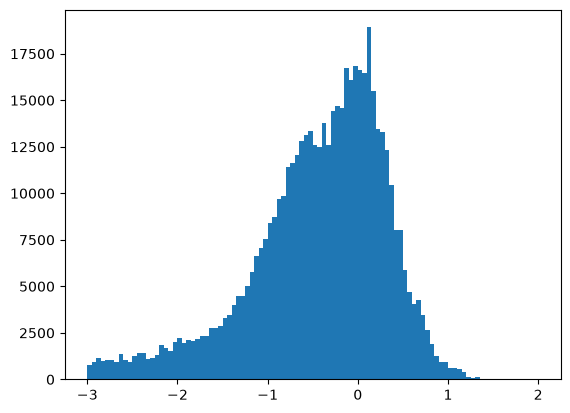

In [29]:
print(hdu.data.max())
print(hdu.data.min())
np.seterr(
    divide="ignore"
)
plt.hist(np.log10(hdu.data.flatten()), range=(-3,2), bins=100);


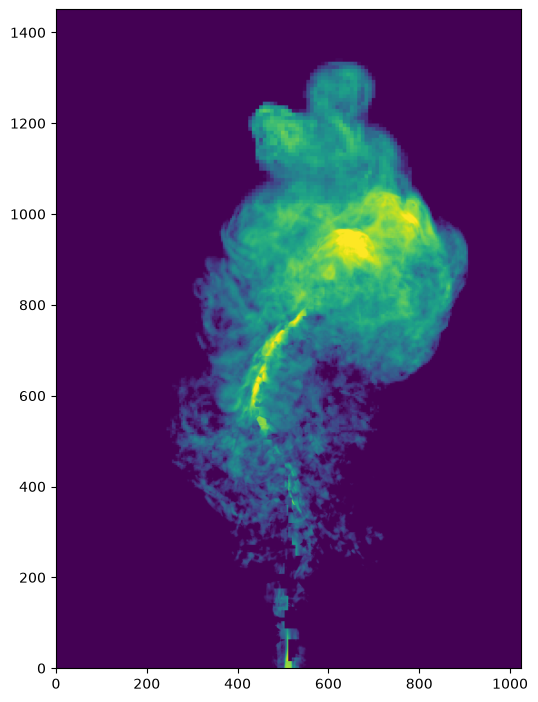

In [30]:
fig = plt.figure(figsize=(6,12))
fig.add_subplot(111)

plt.imshow(np.log10(hdu.data + 1e-3), vmin=-1, vmax=1, origin="lower")


In [31]:
# set up some coordinates
# from the information of data (it is clear that its dimensions are in cm. But in sky coordinates, RA and Dec are not given
# Lets try to find them

dist_obj = 200 * u.Mpc

ra_obj="19h59m28.3566s"
dec_obj ="+40d44m02.096s"

In [32]:
cdelt1= ((hdu.header["CDELT1"]* u.cm/ dist_obj.to("cm")) * u.rad.to("deg"))
cdelt2= ((hdu.header["CDELT2"]* u.cm/dist_obj.to("cm"))* u.rad.to("deg"))
print(cdelt1, cdelt2)

8.74922223983974e-06 8.74922223983974e-06


In [33]:
# Lets use WCS(World Coordinate System)
w= WCS(naxis=2)

w.wcs.crpix=[hdu.data.shape[0]/2, hdu.data.shape[1]/2]

w.wcs.cdelt = [-cdelt1.base, cdelt2.base]

# converting ra and dec into degrees

c= SkyCoord(ra_obj, dec_obj)
w.wcs.crval = [c.ra.deg, c.dec.deg]

w.wcs.cunit= ["deg","deg"]

In [34]:
wcs_header= w.to_header()
hdu.header.update(wcs_header)


In [35]:
hdu.header

XTENSION= 'IMAGE   '           / Image extension                                
BITPIX  =                  -64 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 1024                                                  
NAXIS2  =                 1452                                                  
PCOUNT  =                    0 / number of parameters                           
GCOUNT  =                    1 / number of groups                               
EXTNAME = 'NN_EMISSIVITY_I_LOBE_150.0MHZ' / extension name                      
BTYPE   = 'nn_emissivity_i_lobe_150.0MHz'                                       
BUNIT   = 'Jy/arcsec**2'                                                        
WCSAXES =                    2 / Number of coordinate axes                      
CRPIX1  =                726.0 / Pixel coordinate of reference point            
CRPIX2  =                512

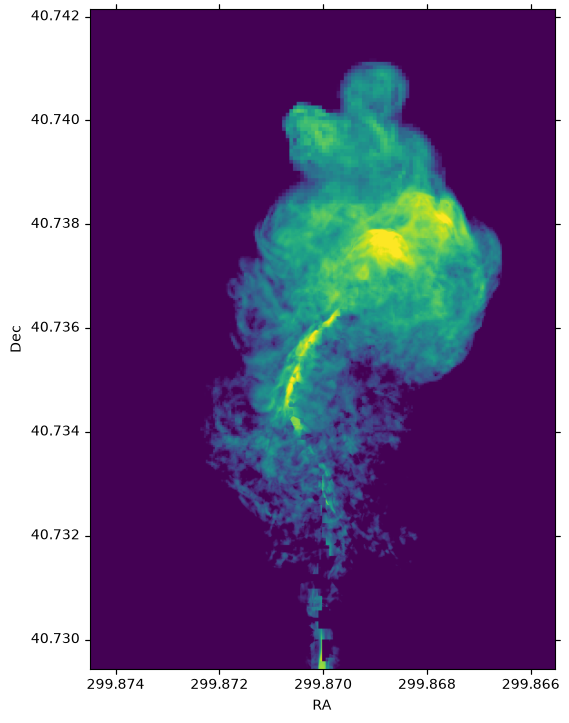

In [36]:
wcs = WCS(hdu.header)

fig = plt.figure(figsize=(6, 12))
fig.add_subplot(111, projection=wcs)
plt.imshow(np.log10(hdu.data + 1e-3), vmin=-1, vmax=1, origin="lower")
plt.xlabel("RA")
plt.ylabel("Dec")

In [42]:
from astropy.convolution import Gaussian2DKernel
# assume our telescope has 1 arcsecond resolution
telescope_resolution = 1 * u.arcsecond

# calculate the sigma in pixels.
# since cdelt is in degrees, we use _.to('deg')
sigma_quantity= telescope_resolution.to("deg") / cdelt2


Original code didn't run. We fixed it here. 

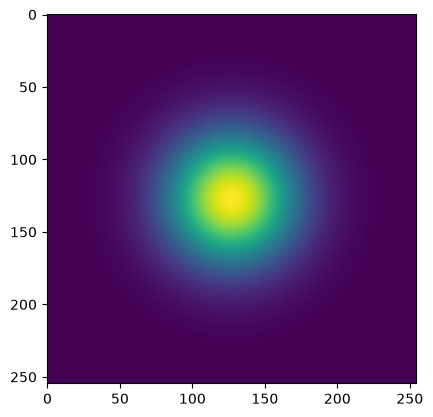

In [45]:
# By default, the Gaussian kernel will go to 4 sigma
# in each direction
sigma = sigma_quantity.value 
psf = Gaussian2DKernel(sigma)

# let's take a look:
plt.imshow(psf.array)

Space telescopes are not perfect. When they look at a sharp point of light (like a star), the telescope's mirrors and lenses naturally blur and smear that light. "Convolution" is the mathematical operation that applies this blur. It blends your sharp, original image with your telescope's blur profile (the PSF or Gaussian kernel you created in your previous step).

In [47]:
convolved_image = convolve_fft(hdu.data, psf, boundary="wrap")

In [48]:
# Convolution with PSF

delta_x_psf= 100  # No. of pixels from the edges
xmin, xmax = -psf.shape[1] -delta_x_psf, -delta_x_psf
ymin, ymax = delta_x_psf, delta_x_psf + psf.shape[0]
convolved_image[xmin:xmax, ymin:ymax]= psf.array / psf.array.max() *10


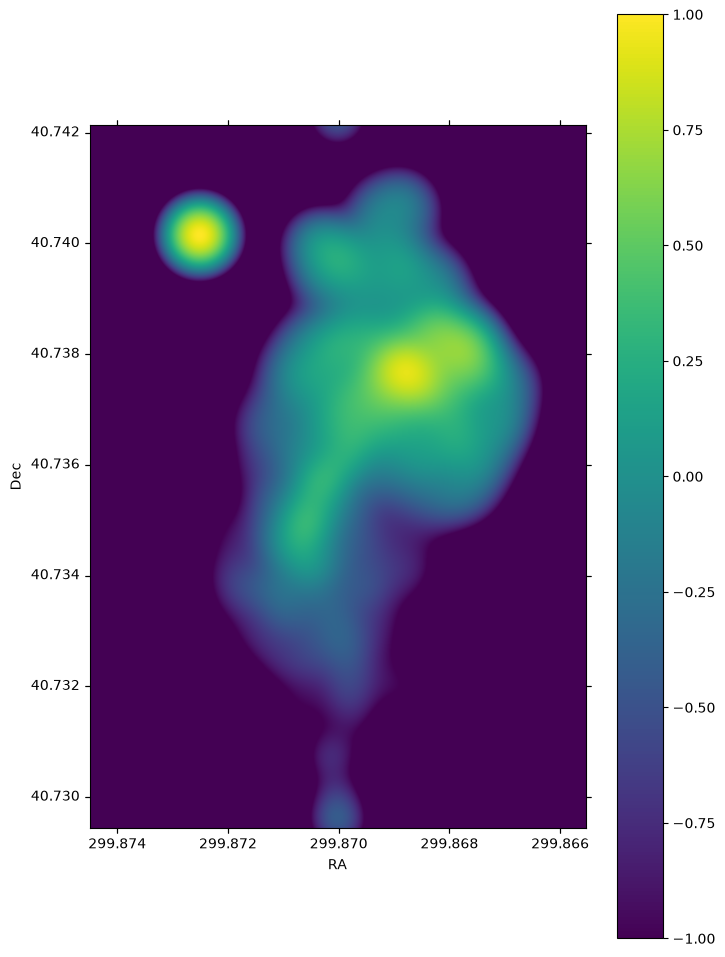

In [50]:
wcs = WCS(hdu.header)
fig = plt.figure(figsize=(8, 12))
i_plot = fig.add_subplot(111, projection=wcs)
plt.imshow(
    np.log10(convolved_image + 1e-3), vmin=-1, vmax=1.0, origin="lower"
, cmap=plt.cm.viridis)
plt.xlabel("RA")
plt.ylabel("Dec")
plt.colorbar()


In [51]:
# Convolve Stokes Q and U images
hdulist.info()


Filename: /home/user/.cache/astropy/download/url/8da27de5aa6b0db633441e82715bedf3/contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  NN_EMISSIVITY_I_LOBE_150.0MHZ    1 ImageHDU        24   (1024, 1452)   float64   


In [ ]:
# Download and open q
file_q = download_file(
    "http://data.astropy.org/tutorials/synthetic-images/synchrotron_q_lobe_0700_150MHz_sm.fits",
    cache=True,
)
hdulist = fits.open(file_q)
hdu_q = hdulist["NN_EMISSIVITY_Q_LOBE_150.0MHZ"]

In [53]:
file_u = download_file(
    "http://data.astropy.org/tutorials/synthetic-images/synchrotron_u_lobe_0700_150MHz_sm.fits",
    cache=True,
)
hdulist = fits.open(file_u)
hdu_u = hdulist["NN_EMISSIVITY_U_LOBE_150.0MHZ"]

In [54]:
hdu_q.header.update(wcs_header)
hdu_u.header.update(wcs_header)

In [55]:
convolved_image_q = convolve_fft(hdu_q.data, psf, boundary="wrap")
convolved_image_u = convolve_fft(hdu_u.data, psf, boundary="wrap")

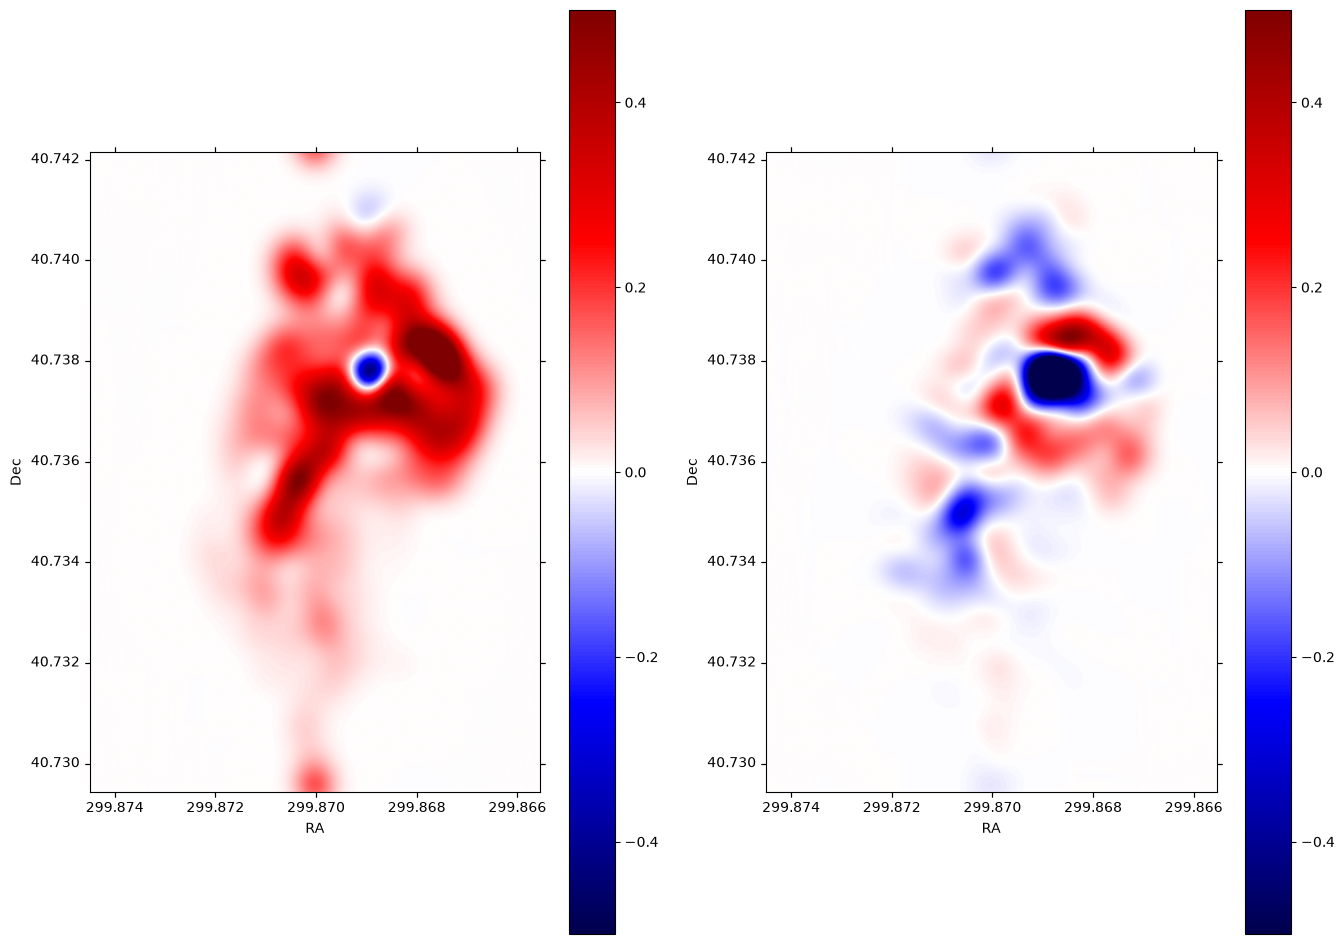

In [56]:
wcs = WCS(hdu.header)
fig = plt.figure(figsize=(16, 12))
fig.add_subplot(121, projection=wcs)
plt.imshow(
    convolved_image_q, cmap="seismic", vmin=-0.5, vmax=0.5, origin="lower"
)  # , cmap=plt.cm.viridis)
plt.xlabel("RA")
plt.ylabel("Dec")
plt.colorbar()

fig.add_subplot(122, projection=wcs)
plt.imshow(
    convolved_image_u, cmap="seismic", vmin=-0.5, vmax=0.5, origin="lower"
)  # , cmap=plt.cm.viridis)

plt.xlabel("RA")
plt.ylabel("Dec")
plt.colorbar()

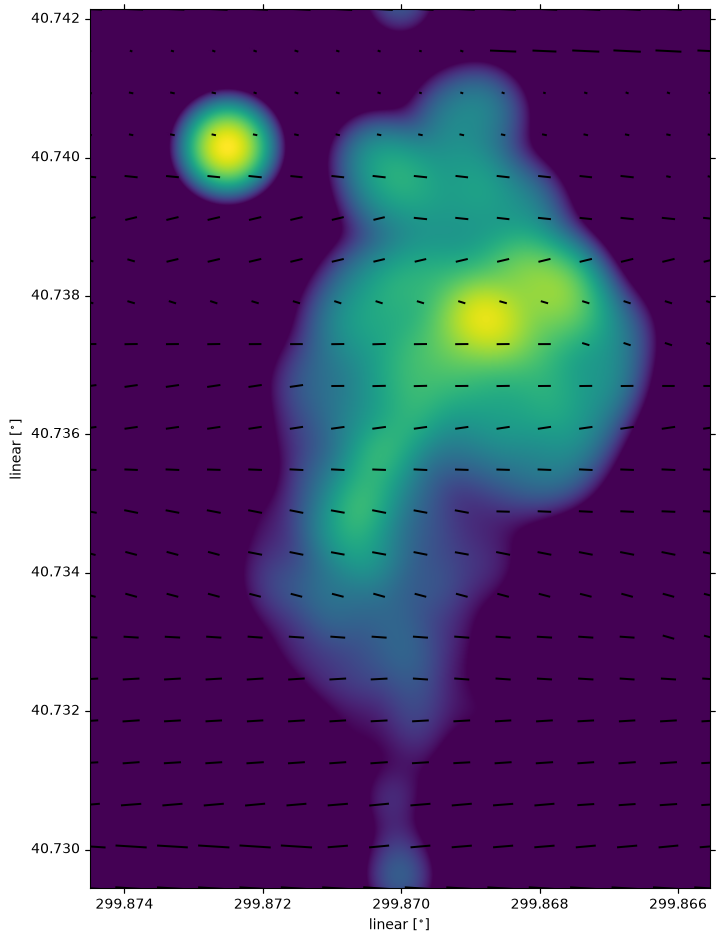

In [62]:
# Calculating polarization angle and fraction for quiver plot

#First, we plot the background image

fig= plt.figure(figsize=(8,16))
i_plot = fig.add_subplot(111, projection= wcs)
i_plot.imshow(np.log10(convolved_image +1e-3), vmin=-1, vmax=1, origin="lower")

# ranges of the axes

xx0, xx1 = i_plot.get_xlim()
yy0, yy1 = i_plot.get_ylim()

#binning factor
factor=[64,66]

#re-binned number of point in each axis
nx_new = convolved_image.shape[1] // factor[0]
ny_new = convolved_image.shape[0] // factor[1]

# These are the positions of the quivers

X,Y = np.meshgrid(
    np.linspace(xx0, xx1, nx_new, endpoint=True),
    np.linspace(yy0,yy1,ny_new, endpoint=True),

)

# bin the data
I_bin = convolved_image.reshape(nx_new, factor[0], ny_new, factor[1]).sum(3).sum(1)
Q_bin= convolved_image_q.reshape(nx_new, factor[0],ny_new, factor[1]).sum(3).sum(1)
U_bin = convolved_image_u.reshape(nx_new, factor[0],ny_new, factor[1]).sum(3).sum(1)


# polarization angle
psi = 0.5 * np.arctan2(U_bin, Q_bin)

#polarization fraction
frac= np.sqrt(Q_bin**2 + U_bin**2)/ I_bin

# mask for low signal area

mask= I_bin <0.1

frac[mask] =0
psi[mask]=0

pixX = frac * np.cos(psi) 
pixY = frac * np.sin(psi)


#keyword arguments for quiverplots
quiveropts= dict(headlength=0,headwidth=1, pivot="middle")
i_plot.quiver(X,Y, pixX, pixY, scale=8, **quiveropts)

